<a href="https://colab.research.google.com/github/SATYA012904/Road_Scene_Semantic_Segmentation/blob/main/Road_Scene_Semantic_Segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("OpenCV:", cv2.__version__)

print("\nAvailable Devices:")
print("CPU:", tf.config.list_physical_devices("CPU"))
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
NumPy: 2.4.6
OpenCV: 4.14.0

Available Devices:
CPU: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import os

dataset_path = "/content/drive/MyDrive/Road_Segmentation_Dataset"

print("Files in dataset folder:")

for file in os.listdir(dataset_path):
    file_path = os.path.join(dataset_path, file)
    size_gb = os.path.getsize(file_path) / (1024 ** 3)

    print(f"{file} : {size_gb:.2f} GB")


Files in dataset folder:
gtFine_trainvaltest.zip : 0.24 GB
leftImg8bit_trainvaltest.zip : 10.80 GB


In [ ]:
import shutil

total, used, free = shutil.disk_usage("/content")

print(f"Total storage: {total / (1024**3):.2f} GB")
print(f"Used storage: {used / (1024**3):.2f} GB")
print(f"Free storage: {free / (1024**3):.2f} GB")


Total storage: 112.64 GB
Used storage: 0.08 GB
Free storage: 112.54 GB


In [ ]:
import zipfile
import os

dataset_path = "/content/drive/MyDrive/Road_Segmentation_Dataset"
extract_path = "/content/cityscapes"

os.makedirs(extract_path, exist_ok=True)

image_zip = os.path.join(
    dataset_path, "leftImg8bit_trainvaltest.zip"
)

with zipfile.ZipFile(image_zip, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Original images extracted successfully!")


Original images extracted successfully!


In [ ]:
for root, dirs, files in os.walk(extract_path):
    level = root.replace(extract_path, "").count(os.sep)

    if level <= 3:
        print("  " * level + os.path.basename(root) + "/")


cityscapes/
  leftImg8bit/
    val/
      frankfurt/
      lindau/
      munster/
    train/
      monchengladbach/
      bochum/
      hamburg/
      bremen/
      weimar/
      tubingen/
      jena/
      aachen/
      stuttgart/
      dusseldorf/
      cologne/
      darmstadt/
      erfurt/
      ulm/
      zurich/
      strasbourg/
      krefeld/
      hanover/
    test/
      mainz/
      berlin/
      munich/
      leverkusen/
      bielefeld/
      bonn/


In [ ]:
import os

extract_path = "/content/cityscapes"

print("Main folders:")
print(os.listdir(extract_path))

print("\nAnnotation folder exists:",
      os.path.exists(os.path.join(extract_path, "gtFine")))


Main folders:
['README', 'leftImg8bit', 'license.txt']

Annotation folder exists: False


In [ ]:
import zipfile
import os

annotation_zip = "/content/drive/MyDrive/Road_Segmentation_Dataset/gtFine_trainvaltest.zip"

print("File exists:", os.path.exists(annotation_zip))
print("File size:", round(os.path.getsize(annotation_zip) / (1024**2), 2), "MB")

with zipfile.ZipFile(annotation_zip, "r") as zip_ref:
    print("\nFirst 20 entries inside ZIP:")

    for name in zip_ref.namelist()[:20]:
        print(name)

    print("\nTotal entries:", len(zip_ref.namelist()))
    print("ZIP integrity:", zip_ref.testzip())


File exists: True
File size: 240.87 MB

First 20 entries inside ZIP:
README
license.txt
gtFine/train/
gtFine/train/jena/
gtFine/train/jena/jena_000020_000019_gtFine_labelIds.png
gtFine/train/jena/jena_000092_000019_gtFine_polygons.json
gtFine/train/jena/jena_000061_000019_gtFine_polygons.json
gtFine/train/jena/jena_000104_000019_gtFine_polygons.json
gtFine/train/jena/jena_000064_000019_gtFine_labelIds.png
gtFine/train/jena/jena_000015_000019_gtFine_instanceIds.png
gtFine/train/jena/jena_000041_000019_gtFine_labelIds.png
gtFine/train/jena/jena_000097_000019_gtFine_labelIds.png
gtFine/train/jena/jena_000071_000019_gtFine_labelIds.png
gtFine/train/jena/jena_000099_000019_gtFine_color.png
gtFine/train/jena/jena_000004_000019_gtFine_instanceIds.png
gtFine/train/jena/jena_000059_000019_gtFine_polygons.json
gtFine/train/jena/jena_000028_000019_gtFine_labelIds.png
gtFine/train/jena/jena_000003_000019_gtFine_polygons.json
gtFine/train/jena/jena_000083_000019_gtFine_color.png
gtFine/train/jena/j

In [ ]:
import zipfile
import os

annotation_zip = "/content/drive/MyDrive/Road_Segmentation_Dataset/gtFine_trainvaltest.zip"
extract_path = "/content/cityscapes"

with zipfile.ZipFile(annotation_zip, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction completed!")

# Verify folders
gt_path = os.path.join(extract_path, "gtFine")

print("\nAnnotation folder exists:", os.path.exists(gt_path))
print("Available folders:", os.listdir(gt_path))

print("\nTraining cities:", len(os.listdir(os.path.join(gt_path, "train"))))
print("Validation cities:", len(os.listdir(os.path.join(gt_path, "val"))))


Extraction completed!

Annotation folder exists: True
Available folders: ['val', 'train', 'test']

Training cities: 18
Validation cities: 3


In [ ]:
import os
import glob

BASE_PATH = "/content/cityscapes"

IMAGE_PATH = os.path.join(BASE_PATH, "leftImg8bit")
MASK_PATH = os.path.join(BASE_PATH, "gtFine")

# Get all training images
train_images = sorted(
    glob.glob(
        os.path.join(IMAGE_PATH, "train", "*", "*_leftImg8bit.png")
    )
)

# Get all training masks
train_masks = sorted(
    glob.glob(
        os.path.join(MASK_PATH, "train", "*", "*_gtFine_labelIds.png")
    )
)

print("Training Images:", len(train_images))
print("Training Masks:", len(train_masks))

print("\nSample Image:")
print(train_images[0])

print("\nSample Mask:")
print(train_masks[0])

Training Images: 2975
Training Masks: 2975

Sample Image:
/content/cityscapes/leftImg8bit/train/aachen/aachen_000000_000019_leftImg8bit.png

Sample Mask:
/content/cityscapes/gtFine/train/aachen/aachen_000000_000019_gtFine_labelIds.png


In [ ]:
import cv2

image = cv2.imread(train_images[0])
mask = cv2.imread(train_masks[0], cv2.IMREAD_UNCHANGED)

print("Image shape:", image.shape)
print("Mask shape:", mask.shape)
print("Mask data type:", mask.dtype)

print("\nUnique label IDs:")
print(sorted(set(mask.flatten()))[:50])

Image shape: (1024, 2048, 3)
Mask shape: (1024, 2048)
Mask data type: uint8

Unique label IDs:
[np.uint8(0), np.uint8(1), np.uint8(3), np.uint8(4), np.uint8(7), np.uint8(8), np.uint8(11), np.uint8(17), np.uint8(20), np.uint8(21), np.uint8(22), np.uint8(23), np.uint8(24), np.uint8(25), np.uint8(26), np.uint8(33)]


In [ ]:
%pip install -q opencv-python-headless matplotlib pandas scikit-learn streamlit pillow tqdm seaborn

# ==========================================
# IMPORT LIBRARIES
# ==========================================

# Deep Learning
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Numerical and Data Processing
import numpy as np
import pandas as pd

# Image Processing
import cv2
from PIL import Image

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning Metrics
from sklearn.metrics import confusion_matrix

# File and Directory Handling
import os
import glob
import shutil
import zipfile
import json
import random
from pathlib import Path

# Progress Monitoring
from tqdm.auto import tqdm

# System Information
import sys
import time


In [ ]:
import numpy as np

NUM_CLASSES = 19
IGNORE_LABEL = 255

label_mapping = {
    7: 0, 8: 1, 11: 2, 12: 3, 13: 4,
    17: 5, 19: 6, 20: 7, 21: 8, 22: 9,
    23: 10, 24: 11, 25: 12, 26: 13,
    27: 14, 28: 15, 31: 16, 32: 17, 33: 18
}

id_to_trainid = np.full(256, IGNORE_LABEL, dtype=np.uint8)

for original_id, train_id in label_mapping.items():
    id_to_trainid[original_id] = train_id

print("Label mapping initialized successfully!")

Label mapping initialized successfully!


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread(train_images[0])
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

original_mask = cv2.imread(
    train_masks[0],
    cv2.IMREAD_UNCHANGED
)

train_mask = id_to_trainid[original_mask]

print("Original IDs:", np.unique(original_mask))
print("Training IDs:", np.unique(train_mask))
print("Converted mask shape:", train_mask.shape)

Original IDs: [ 0  1  3  4  7  8 11 17 20 21 22 23 24 25 26 33]
Training IDs: [  0   1   2   5   7   8   9  10  11  12  13  18 255]
Converted mask shape: (1024, 2048)


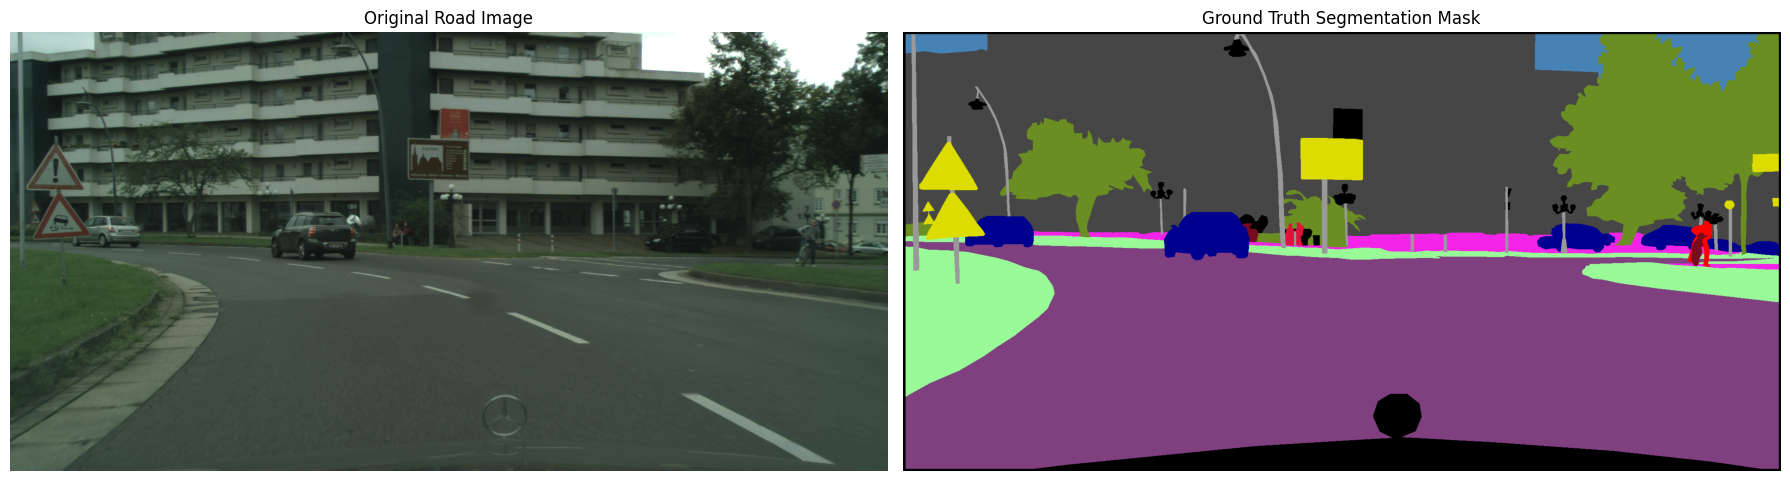

In [ ]:
# Cityscapes colors for the 19 training classes
cityscapes_colors = [
    (128, 64, 128),   # Road
    (244, 35, 232),   # Sidewalk
    (70, 70, 70),     # Building
    (102, 102, 156),  # Wall
    (190, 153, 153),  # Fence
    (153, 153, 153),  # Pole
    (250, 170, 30),   # Traffic Light
    (220, 220, 0),    # Traffic Sign
    (107, 142, 35),   # Vegetation
    (152, 251, 152),  # Terrain
    (70, 130, 180),   # Sky
    (220, 20, 60),    # Person
    (255, 0, 0),      # Rider
    (0, 0, 142),      # Car
    (0, 0, 70),       # Truck
    (0, 60, 100),     # Bus
    (0, 80, 100),     # Train
    (0, 0, 230),     # Motorcycle
    (119, 11, 32)     # Bicycle
]

# Black color for ignored pixels
color_table = np.array([(0, 0, 0)] + cityscapes_colors, dtype=np.uint8)

# Shift valid training IDs from 0–18 to 1–19.
# Ignore label 255 is displayed as black (index 0).
display_mask = np.where(
    train_mask == IGNORE_LABEL,
    0,
    train_mask + 1
)

rgb_mask = color_table[display_mask]

# Display image and mask
plt.figure(figsize=(18, 7))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Road Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(rgb_mask)
plt.title("Ground Truth Segmentation Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Target image dimensions
IMG_HEIGHT = 512
IMG_WIDTH = 1024

NUM_CLASSES = 19
IGNORE_LABEL = 255

def preprocess_pair(image_path, mask_path):

    # Read original image
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Read original annotation mask
    mask = cv2.imread(mask_path, cv2.IMREAD_UNCHANGED)

    # Convert original label IDs into training IDs
    mask = id_to_trainid[mask]

    # Resize image using bilinear interpolation
    image = cv2.resize(
        image,
        (IMG_WIDTH, IMG_HEIGHT),
        interpolation=cv2.INTER_LINEAR
    )

    # Resize mask using nearest-neighbor interpolation
    mask = cv2.resize(
        mask,
        (IMG_WIDTH, IMG_HEIGHT),
        interpolation=cv2.INTER_NEAREST
    )

    # Normalize image pixels from 0-255 to 0-1
    image = image.astype(np.float32) / 255.0

    # Keep mask values as integer class IDs
    mask = mask.astype(np.int32)

    return image, mask

In [ ]:
sample_image, sample_mask = preprocess_pair(
    train_images[0],
    train_masks[0]
)

print("Processed Image Shape:", sample_image.shape)
print("Processed Mask Shape:", sample_mask.shape)

print("Image Data Type:", sample_image.dtype)
print("Mask Data Type:", sample_mask.dtype)

print("Image Pixel Range:",
      sample_image.min(), "to", sample_image.max())

print("Training Mask IDs:", np.unique(sample_mask))

Processed Image Shape: (512, 1024, 3)
Processed Mask Shape: (512, 1024)
Image Data Type: float32
Mask Data Type: int32
Image Pixel Range: 0.05490196 to 1.0
Training Mask IDs: [  0   1   2   5   7   8   9  10  11  12  13  18 255]


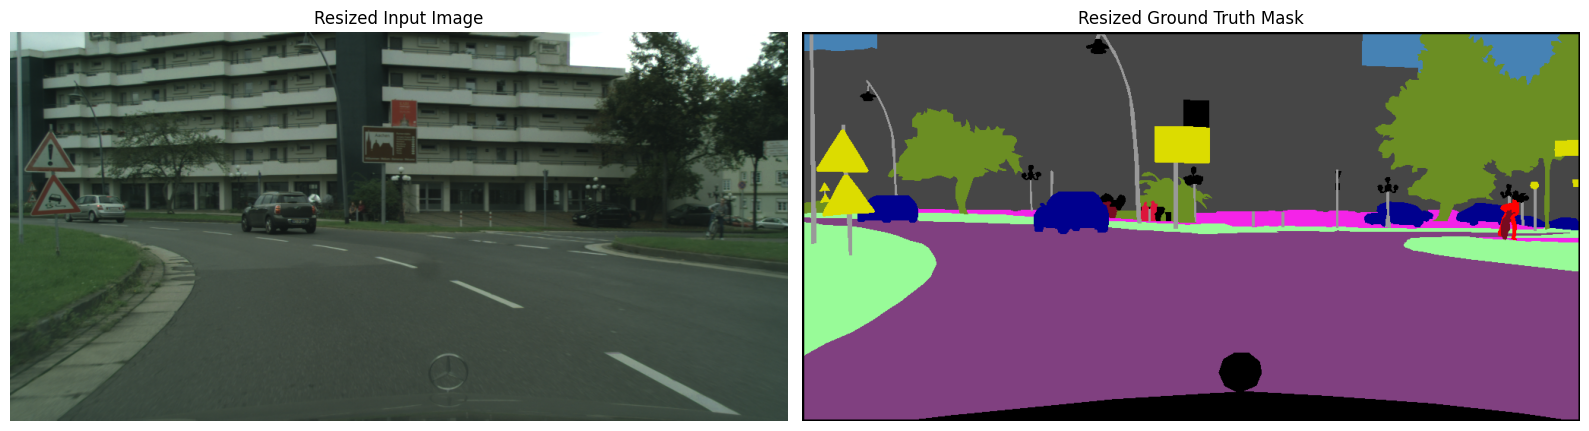

In [ ]:
display_mask = np.where(
    sample_mask == IGNORE_LABEL,
    0,
    sample_mask + 1
)

rgb_mask = color_table[display_mask]

plt.figure(figsize=(16, 6))

plt.subplot(1, 2, 1)
plt.imshow(sample_image)
plt.title("Resized Input Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(rgb_mask)
plt.title("Resized Ground Truth Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Training paths
train_images = sorted(
    glob.glob(os.path.join(IMAGE_PATH, "train", "*", "*_leftImg8bit.png"))
)

train_masks = sorted(
    glob.glob(os.path.join(MASK_PATH, "train", "*", "*_gtFine_labelIds.png"))
)

# Validation paths
val_images = sorted(
    glob.glob(os.path.join(IMAGE_PATH, "val", "*", "*_leftImg8bit.png"))
)

val_masks = sorted(
    glob.glob(os.path.join(MASK_PATH, "val", "*", "*_gtFine_labelIds.png"))
)

print("Training pairs:", len(train_images), len(train_masks))
print("Validation pairs:", len(val_images), len(val_masks))

Training pairs: 2975 2975
Validation pairs: 500 500


In [ ]:
# TensorFlow constants
IMG_HEIGHT = 512
IMG_WIDTH = 1024
BATCH_SIZE = 4

label_lookup = tf.constant(id_to_trainid, dtype=tf.uint8)

def load_and_preprocess(image_path, mask_path, training=False):

    # Read image
    image = tf.io.read_file(image_path)
    image = tf.image.decode_png(image, channels=3)

    # Read annotation mask
    mask = tf.io.read_file(mask_path)
    mask = tf.image.decode_png(mask, channels=1)

    # Resize image
    image = tf.image.resize(
        image,
        [IMG_HEIGHT, IMG_WIDTH],
        method="bilinear"
    )

    # Resize mask using nearest neighbor
    mask = tf.image.resize(
        mask,
        [IMG_HEIGHT, IMG_WIDTH],
        method="nearest"
    )

    # Convert image to float and normalize
    image = tf.cast(image, tf.float32) / 255.0

    # Convert original IDs to training IDs
    mask = tf.cast(mask, tf.uint8)
    mask = tf.gather(label_lookup, mask)
    mask = tf.squeeze(mask, axis=-1)

    # Apply the same horizontal flip to image and mask
    if training:
        should_flip = tf.random.uniform(()) > 0.5

        image, mask = tf.cond(
            should_flip,
            lambda: (
                tf.image.flip_left_right(image),
                tf.image.flip_left_right(mask[..., tf.newaxis])[..., 0]
            ),
            lambda: (image, mask)
        )

    return image, tf.cast(mask, tf.int32)

In [ ]:
# Training paths
train_images = sorted(
    glob.glob(os.path.join(IMAGE_PATH, "train", "*", "*_leftImg8bit.png"))
)

train_masks = sorted(
    glob.glob(os.path.join(MASK_PATH, "train", "*", "*_gtFine_labelIds.png"))
)

# Validation paths
val_images = sorted(
    glob.glob(os.path.join(IMAGE_PATH, "val", "*", "*_leftImg8bit.png"))
)

val_masks = sorted(
    glob.glob(os.path.join(MASK_PATH, "val", "*", "*_gtFine_labelIds.png"))
)

print("Training pairs:", len(train_images), len(train_masks))
print("Validation pairs:", len(val_images), len(val_masks))

Training pairs: 2975 2975
Validation pairs: 500 500


In [ ]:
# TensorFlow constants
IMG_HEIGHT = 512
IMG_WIDTH = 1024
BATCH_SIZE = 4

label_lookup = tf.constant(id_to_trainid, dtype=tf.uint8)

def load_and_preprocess(image_path, mask_path, training=False):

    # Read image
    image = tf.io.read_file(image_path)
    image = tf.image.decode_png(image, channels=3)

    # Read annotation mask
    mask = tf.io.read_file(mask_path)
    mask = tf.image.decode_png(mask, channels=1)

    # Resize image
    image = tf.image.resize(
        image,
        [IMG_HEIGHT, IMG_WIDTH],
        method="bilinear"
    )

    # Resize mask using nearest neighbor
    mask = tf.image.resize(
        mask,
        [IMG_HEIGHT, IMG_WIDTH],
        method="nearest"
    )

    # Convert image to float and normalize
    image = tf.cast(image, tf.float32) / 255.0

    # Convert original IDs to training IDs
    mask = tf.cast(mask, tf.uint8)
    mask = tf.gather(label_lookup, mask)
    mask = tf.squeeze(mask, axis=-1)

    # Apply the same horizontal flip to image and mask
    if training:
        should_flip = tf.random.uniform(()) > 0.5

        image, mask = tf.cond(
            should_flip,
            lambda: (
                tf.image.flip_left_right(image),
                tf.image.flip_left_right(mask[..., tf.newaxis])[..., 0]
            ),
            lambda: (image, mask)
        )

    return image, tf.cast(mask, tf.int32)

In [ ]:
# Redefining the preprocess function with the uint8 -> int32 index casting fix for tf.gather
def load_and_preprocess(image_path, mask_path, training=False):
    # Read image
    image = tf.io.read_file(image_path)
    image = tf.image.decode_png(image, channels=3)

    # Read annotation mask
    mask = tf.io.read_file(mask_path)
    mask = tf.image.decode_png(mask, channels=1)

    # Resize image
    image = tf.image.resize(
        image,
        [IMG_HEIGHT, IMG_WIDTH],
        method="bilinear"
    )

    # Resize mask using nearest neighbor
    mask = tf.image.resize(
        mask,
        [IMG_HEIGHT, IMG_WIDTH],
        method="nearest"
    )

    # Convert image to float and normalize
    # Apply MobileNetV2 ImageNet preprocessing: [0, 255] -> [-1, 1]
    image = tf.cast(image, tf.float32)
    image = keras.applications.mobilenet_v2.preprocess_input(image)

    # Convert original IDs to training IDs
    # FIX: Cast the mask to tf.int32 so that tf.gather can use it as indices
    mask = tf.cast(mask, tf.int32)
    mask = tf.gather(label_lookup, mask)
    mask = tf.squeeze(mask, axis=-1)

    # Apply the same horizontal flip to image and mask
    if training:
        should_flip = tf.random.uniform(()) > 0.5

        image, mask = tf.cond(
            should_flip,
            lambda: (
                tf.image.flip_left_right(image),
                tf.image.flip_left_right(mask[..., tf.newaxis])[..., 0]
            ),
            lambda: (image, mask)
        )

    return image, tf.cast(mask, tf.int32)

def create_dataset(image_paths, mask_paths, training=False):
    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, mask_paths)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=500,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        lambda img, msk: load_and_preprocess(img, msk, training),
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

train_dataset = create_dataset(
    train_images,
    train_masks,
    training=True
)

val_dataset = create_dataset(
    val_images,
    val_masks,
    training=False
)

print("TensorFlow datasets created successfully!")

TensorFlow datasets created successfully!


In [ ]:
for batch_images, batch_masks in train_dataset.take(1):

    print("Batch image shape:", batch_images.shape)
    print("Batch mask shape:", batch_masks.shape)

    print("Image data type:", batch_images.dtype)
    print("Mask data type:", batch_masks.dtype)

    print("Image pixel range:",
          tf.reduce_min(batch_images).numpy(),
          "to",
          tf.reduce_max(batch_images).numpy())

    print("Mask IDs:", np.unique(batch_masks.numpy()))

Batch image shape: (4, 512, 1024, 3)
Batch mask shape: (4, 512, 1024)
Image data type: <dtype: 'float32'>
Mask data type: <dtype: 'int32'>
Image pixel range: -1.0 to 1.0
Mask IDs: [  0   1   2   3   4   5   6   7   8   9  10  11  12  13  17  18 255]


In [ ]:
# ==========================================
# U-NET WITH MOBILENETV2 ENCODER
# ==========================================

def conv_block(x, filters):

    x = layers.Conv2D(
        filters, 3, padding="same", use_bias=False
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.Conv2D(
        filters, 3, padding="same", use_bias=False
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    return x


def decoder_block(x, skip, filters):

    x = layers.UpSampling2D(
        size=(2, 2),
        interpolation="bilinear"
    )(x)

    if skip is not None:
        x = layers.Concatenate()([x, skip])

    x = conv_block(x, filters)

    return x


def build_unet():

    inputs = keras.Input(
        shape=(IMG_HEIGHT, IMG_WIDTH, 3)
    )

    # Pretrained MobileNetV2 encoder
    backbone = keras.applications.MobileNetV2(
        input_tensor=inputs,
        include_top=False,
        weights="imagenet"
    )

    # Freeze encoder initially
    backbone.trainable = False

    # Extract encoder feature maps
    skip1 = backbone.get_layer(
        "block_1_expand_relu"
    ).output

    skip2 = backbone.get_layer(
        "block_3_expand_relu"
    ).output

    skip3 = backbone.get_layer(
        "block_6_expand_relu"
    ).output

    skip4 = backbone.get_layer(
        "block_13_expand_relu"
    ).output

    encoder_output = backbone.get_layer(
        "block_16_project"
    ).output

    # Decoder
    x = decoder_block(encoder_output, skip4, 256)
    x = decoder_block(x, skip3, 128)
    x = decoder_block(x, skip2, 64)
    x = decoder_block(x, skip1, 32)

    # Final upsampling
    x = layers.UpSampling2D(
        size=(2, 2),
        interpolation="bilinear"
    )(x)

    x = conv_block(x, 16)

    # 19-class segmentation output
    outputs = layers.Conv2D(
        NUM_CLASSES,
        kernel_size=1,
        activation="softmax"
    )(x)

    model = keras.Model(
        inputs=inputs,
        outputs=outputs,
        name="UNet_MobileNetV2"
    )

    return model


unet_model = build_unet()

print("U-Net model created successfully!")
print("Input shape:", unet_model.input_shape)
print("Output shape:", unet_model.output_shape)

print(
    "Total parameters:",
    f"{unet_model.count_params():,}"
)

/tmp/ipykernel_911/2952135907.py:46: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  backbone = keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
U-Net model created successfully!
Input shape: (None, 512, 1024, 3)
Output shape: (None, 512, 1024, 19)
Total parameters: 5,419,779


In [ ]:
print("Total Parameters:",
      f"{unet_model.count_params():,}")

print("Trainable Parameters:",
      f"{sum(np.prod(v.shape) for v in unet_model.trainable_variables):,}")

print("Non-trainable Parameters:",
      f"{sum(np.prod(v.shape) for v in unet_model.non_trainable_variables):,}")

Total Parameters: 5,419,779
Trainable Parameters: 3,575,811
Non-trainable Parameters: 1,843,968


In [ ]:
def masked_sparse_categorical_crossentropy(y_true, y_pred):

    # Convert ground truth to integer
    y_true = tf.cast(y_true, tf.int32)

    # Identify valid pixels (exclude 255)
    valid_mask = tf.not_equal(y_true, IGNORE_LABEL)

    # Replace ignored labels with 0 temporarily
    safe_labels = tf.where(
        valid_mask,
        y_true,
        tf.zeros_like(y_true)
    )

    # Calculate pixel-wise cross entropy
    loss = keras.losses.sparse_categorical_crossentropy(
        safe_labels,
        y_pred
    )

    # Keep only valid pixel losses
    valid_mask = tf.cast(valid_mask, tf.float32)

    loss = loss * valid_mask

    # Average over valid pixels only
    return tf.reduce_sum(loss) / (
        tf.reduce_sum(valid_mask) + 1e-7
    )

In [ ]:
for batch_images, batch_masks in train_dataset.take(1):

    predictions = unet_model(batch_images, training=False)

    test_loss = masked_sparse_categorical_crossentropy(
        batch_masks,
        predictions
    )

    print("Prediction shape:", predictions.shape)
    print("Test Loss:", test_loss.numpy())

Prediction shape: (4, 512, 1024, 19)
Test Loss: 3.5017905


In [ ]:
BATCH_SIZE = 2
EPOCHS = 10
LEARNING_RATE = 0.001

# Recreate datasets with the new batch size
train_dataset = create_dataset(
    train_images,
    train_masks,
    training=True
)

val_dataset = create_dataset(
    val_images,
    val_masks,
    training=False
)

# Compile model
unet_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss=masked_sparse_categorical_crossentropy
)

print("U-Net compilation completed!")

U-Net compilation completed!


In [ ]:
# Save the best model based on validation loss
checkpoint_callback = keras.callbacks.ModelCheckpoint(
    filepath="/content/best_unet_model.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

# Stop training when validation loss stops improving
early_stopping_callback = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

# Reduce learning rate when validation loss plateaus
reduce_lr_callback = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

callbacks = [
    checkpoint_callback,
    early_stopping_callback,
    reduce_lr_callback
]

print("Training callbacks configured successfully!")

Training callbacks configured successfully!


In [ ]:
print("Training images:", len(train_images))
print("Validation images:", len(val_images))
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Input resolution:", IMG_HEIGHT, "x", IMG_WIDTH)
print("Callbacks:", len(callbacks))

Training images: 2975
Validation images: 500
Batch size: 2
Epochs: 10
Learning rate: 0.001
Input resolution: 512 x 1024
Callbacks: 3


In [ ]:
# Create a permanent model storage directory
MODEL_DIR = "/content/drive/MyDrive/Road_Segmentation_Models"

os.makedirs(MODEL_DIR, exist_ok=True)

# Update checkpoint callback
checkpoint_callback = keras.callbacks.ModelCheckpoint(
    filepath=os.path.join(MODEL_DIR, "best_unet_model.keras"),
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

callbacks = [
    checkpoint_callback,
    early_stopping_callback,
    reduce_lr_callback
]

print("Model directory:", MODEL_DIR)
print("Checkpoint path:",
      os.path.join(MODEL_DIR, "best_unet_model.keras"))

Model directory: /content/drive/MyDrive/Road_Segmentation_Models
Checkpoint path: /content/drive/MyDrive/Road_Segmentation_Models/best_unet_model.keras


In [ ]:
train_dataset = create_dataset(train_images, train_masks, training=True)
val_dataset = create_dataset(val_images, val_masks, training=False)

In [ ]:
images, masks = next(iter(train_dataset))

print("Image shape:", images.shape)
print("Mask shape:", masks.shape)
print("Image minimum:", tf.reduce_min(images).numpy())
print("Image maximum:", tf.reduce_max(images).numpy())
print("Mask IDs:", tf.unique(tf.reshape(masks, [-1]))[0].numpy())

Image shape: (2, 512, 1024, 3)
Mask shape: (2, 512, 1024)
Image minimum: -0.8980392
Image maximum: 1.0
Mask IDs: [255   2   7   8  11   0   1   5  10  13  15   6   9]


In [ ]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
print("GPU:", tf.config.list_physical_devices("GPU"))

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import tensorflow as tf

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"[SUCCESS] GPU is active and detected!")
    for gpu in gpus:
        print(f" - Device Name: {gpu.name}")
    # Display actual GPU hardware information
    print(" - Hardware Card Name:", tf.test.gpu_device_name())
else:
    print("[WARNING] GPU not detected. Please make sure you selected 'T4 GPU' under 'Runtime' -> 'Change runtime type'.")

[SUCCESS] GPU is active and detected!
 - Device Name: /physical_device:GPU:0
 - Hardware Card Name: /device:GPU:0


In [ ]:
history = unet_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/10
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 0s 209ms/step - loss: 0.8824
Epoch 1: val_loss improved from None to 0.42643, saving model to /content/drive/MyDrive/Road_Segmentation_Models/best_unet_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Road_Segmentation_Models/best_unet_model.keras
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 425s 241ms/step - loss: 0.5851 - val_loss: 0.4264 - learning_rate: 0.0010
Epoch 2/10
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step - loss: 0.3595